# Financial Risk Analysis & Loan Default Prediction

## Project Overview

This project analyzes loan data to identify patterns and factors associated with loan default risk. It uses exploratory data analysis, data preprocessing, and machine learning to compare Logistic Regression, Random Forest, and Gradient Boosting models.

**Dataset:** 255,347 loan records  
**Target:** `Default`  
**Tools:** Python, Pandas, NumPy, Scikit-learn, Matplotlib


## 1. Import Libraries

In [ ]:
import pandas as pd

df = pd.read_csv('Loan_default.csv')

In [7]:
import os

print(os.listdir())

['Intro.ipynb', 'Untitled.ipynb', 'Untitled1.ipynb', 'Untitled2.ipynb', 'customer_shopping_behavior.csv', 'sqlite.ipynb', 'cpp-tiny-ray-tracer.ipynb', 'Lorenz.ipynb', 'cpp.ipynb', 'r.ipynb', 'cpp-third-party-libs.ipynb']


In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the dataset
df = pd.read_csv("Loan_default.csv")   # Change the file name if needed

# Use default matplotlib style
plt.style.use("default")

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the dataset
df = pd.read_csv("Loan_default.csv")

# Check the first five rows
df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [10]:
print(df.columns.tolist())


['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default']


Text(0, 0.5, 'Number of Borrowers')

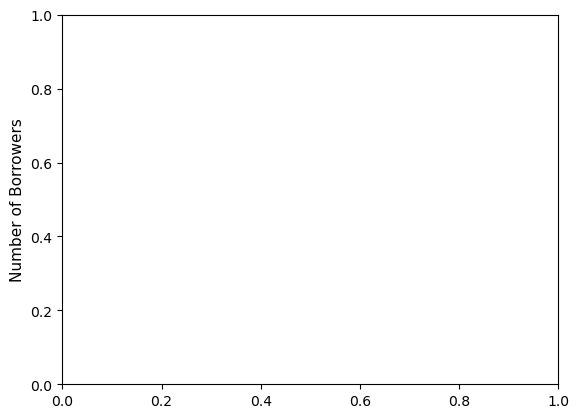

In [12]:
plt.ylabel('Number of Borrowers', fontsize=11)

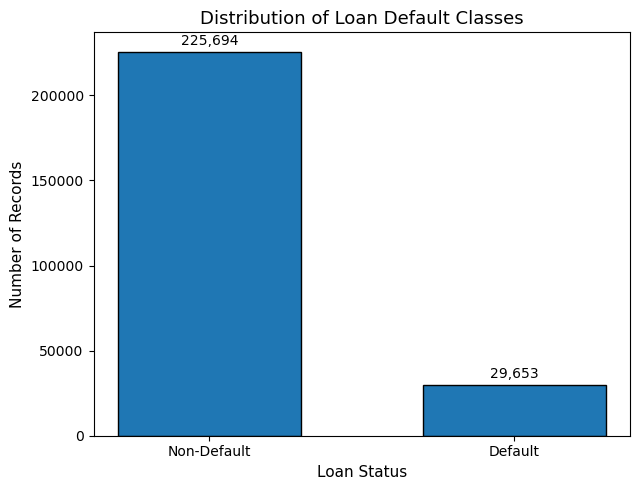

In [14]:
import matplotlib.pyplot as plt

# Count loan default classes
counts = df['Default'].value_counts().sort_index()

# Create figure
plt.figure(figsize=(6.5,5))

bars = plt.bar(
    ['Non-Default', 'Default'],
    counts.values,
    color='#1f77b4',
    edgecolor='black',
    width=0.6
)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + (counts.max() * 0.01),
        f'{int(height):,}',
        ha='center',
        va='bottom',
        fontsize=10
    )

# Title and labels
plt.title('Distribution of Loan Default Classes', fontsize=13)
plt.xlabel('Loan Status', fontsize=11)
plt.ylabel('Number of Records', fontsize=11)

plt.tight_layout()

# Save image
plt.savefig(
    'Figure_3_2_Distribution_of_Loan_Default_Classes.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Text(0, 0.5, 'Number of Borrowers')

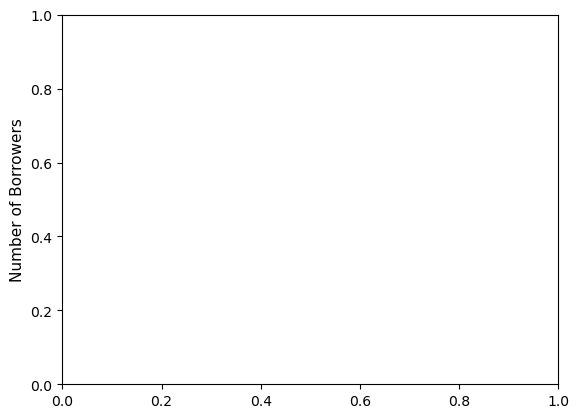

In [13]:
plt.ylabel('Number of Borrowers', fontsize=11)

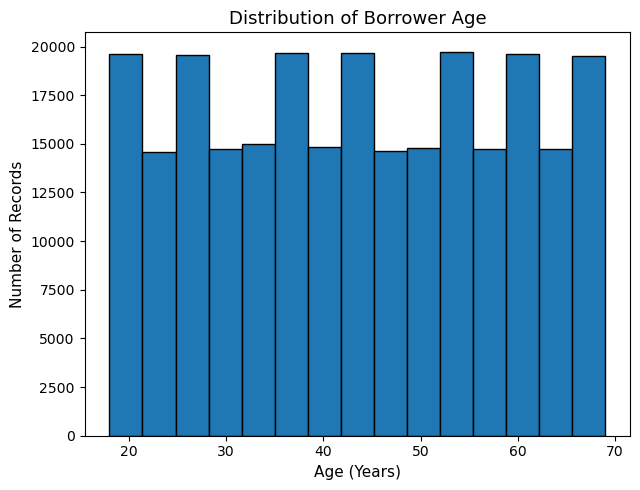

In [16]:
# Figure 3.3 - Distribution of Borrower Age

plt.figure(figsize=(6.5,5))

plt.hist(
    df['Age'],
    bins=15,
    color='#1f77b4',
    edgecolor='black',
    linewidth=1
)

plt.title('Distribution of Borrower Age', fontsize=13)
plt.xlabel('Age (Years)', fontsize=11)
plt.ylabel('Number of Records', fontsize=11)

plt.tight_layout()

plt.savefig(
    'Figure_3_3_Distribution_of_Borrower_Age.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

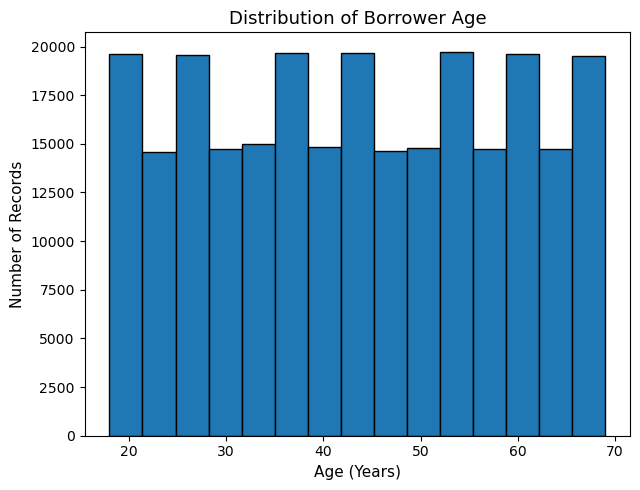

In [17]:
# Figure 3.3 - Distribution of Borrower Age

plt.figure(figsize=(6.5,5))

plt.hist(
    df['Age'],
    bins=15,
    color='#1f77b4',
    edgecolor='black',
    linewidth=1
)

plt.title('Distribution of Borrower Age', fontsize=13)
plt.xlabel('Age (Years)', fontsize=11)
plt.ylabel('Number of Records', fontsize=11)

plt.tight_layout()

plt.savefig(
    'Figure_3_3_Distribution_of_Borrower_Age.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

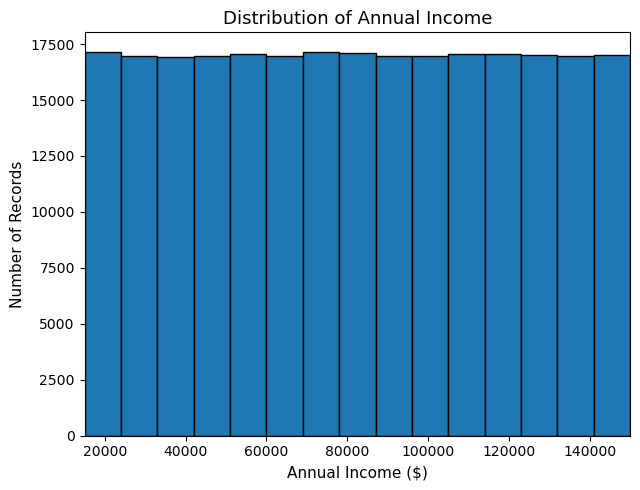

In [18]:
# Figure 3.4 - Distribution of Annual Income

plt.figure(figsize=(6.5,5))

plt.hist(
    df['Income'],
    bins=15,
    color='#1f77b4',
    edgecolor='black',
    linewidth=1
)

plt.title('Distribution of Annual Income', fontsize=13)
plt.xlabel('Annual Income ($)', fontsize=11)
plt.ylabel('Number of Records', fontsize=11)

# Display full numbers instead of scientific notation
plt.ticklabel_format(style='plain', axis='x')

plt.xlim(df['Income'].min(), df['Income'].max())

plt.tight_layout()

plt.savefig(
    'Figure_3_4_Distribution_of_Annual_Income.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

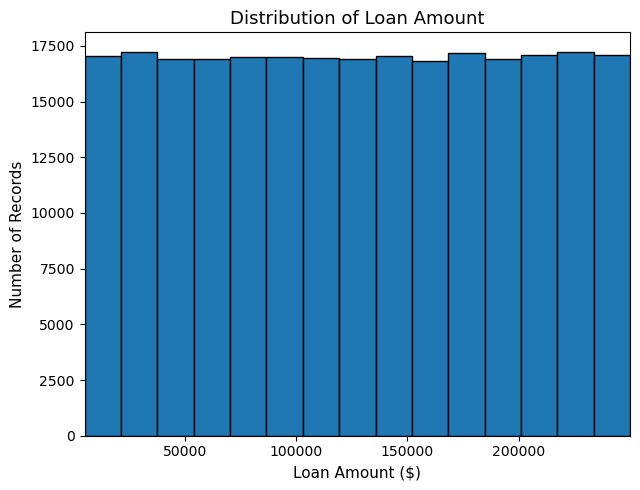

In [19]:
# Figure 3.5 - Distribution of Loan Amount

plt.figure(figsize=(6.5,5))

plt.hist(
    df['LoanAmount'],
    bins=15,
    color='#1f77b4',
    edgecolor='black',
    linewidth=1
)

plt.title('Distribution of Loan Amount', fontsize=13)
plt.xlabel('Loan Amount ($)', fontsize=11)
plt.ylabel('Number of Records', fontsize=11)

# Display full numbers on the x-axis
plt.ticklabel_format(style='plain', axis='x')

plt.xlim(df['LoanAmount'].min(), df['LoanAmount'].max())

plt.tight_layout()

plt.savefig(
    'Figure_3_5_Distribution_of_Loan_Amount.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

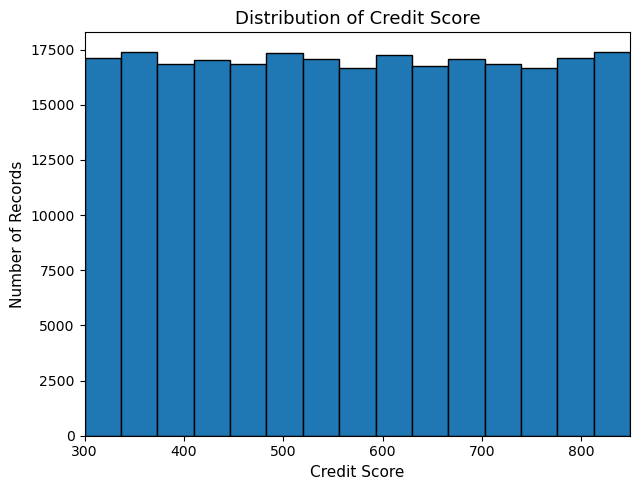

In [20]:
# Figure 3.6 - Distribution of Credit Score

plt.figure(figsize=(6.5,5))

plt.hist(
    df['CreditScore'],
    bins=15,
    color='#1f77b4',
    edgecolor='black',
    linewidth=1
)

plt.title('Distribution of Credit Score', fontsize=13)
plt.xlabel('Credit Score', fontsize=11)
plt.ylabel('Number of Records', fontsize=11)

plt.xlim(df['CreditScore'].min(), df['CreditScore'].max())

plt.tight_layout()

plt.savefig(
    'Figure_3_6_Distribution_of_Credit_Score.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

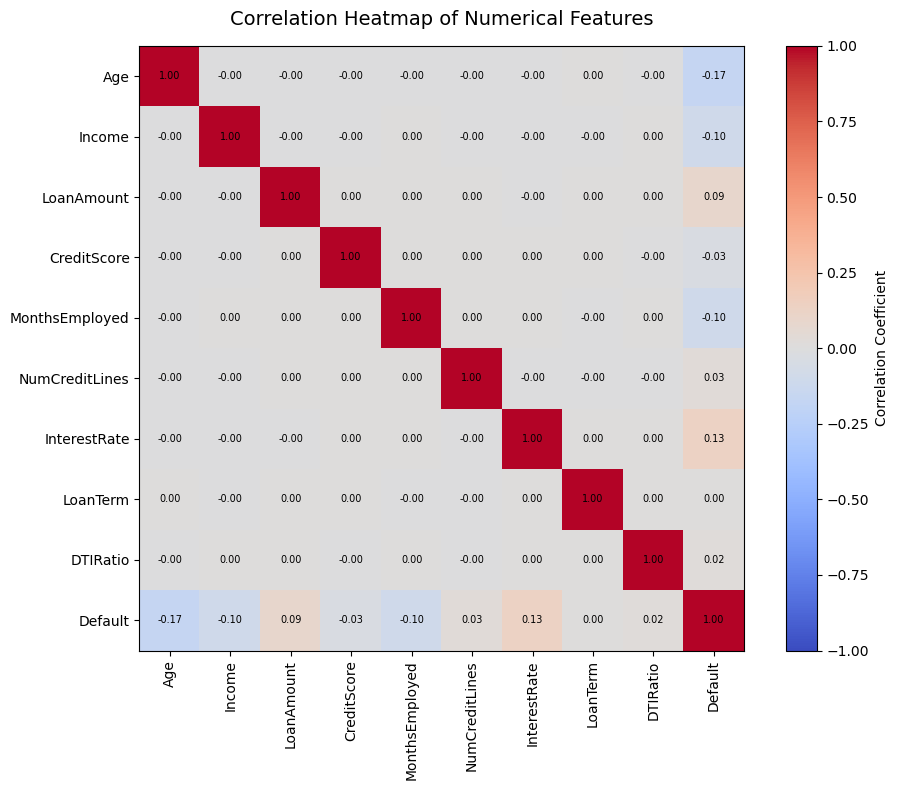

In [22]:
# Figure 3.7 - Correlation Heatmap of Numerical Features

import numpy as np

# Select only numerical columns
numeric_df = df.select_dtypes(include=['number'])

# Compute correlation matrix
corr = numeric_df.corr()

# Create figure
plt.figure(figsize=(10,8))

# Plot heatmap
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)

# Color bar
plt.colorbar(label='Correlation Coefficient')

# Axis labels
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

# Add correlation values inside cells
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(
            j,
            i,
            f"{corr.iloc[i, j]:.2f}",
            ha='center',
            va='center',
            fontsize=7,
            color='black'
        )

plt.title("Correlation Heatmap of Numerical Features", fontsize=14, pad=15)

plt.tight_layout()

plt.savefig(
    "Figure_3_7_Correlation_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

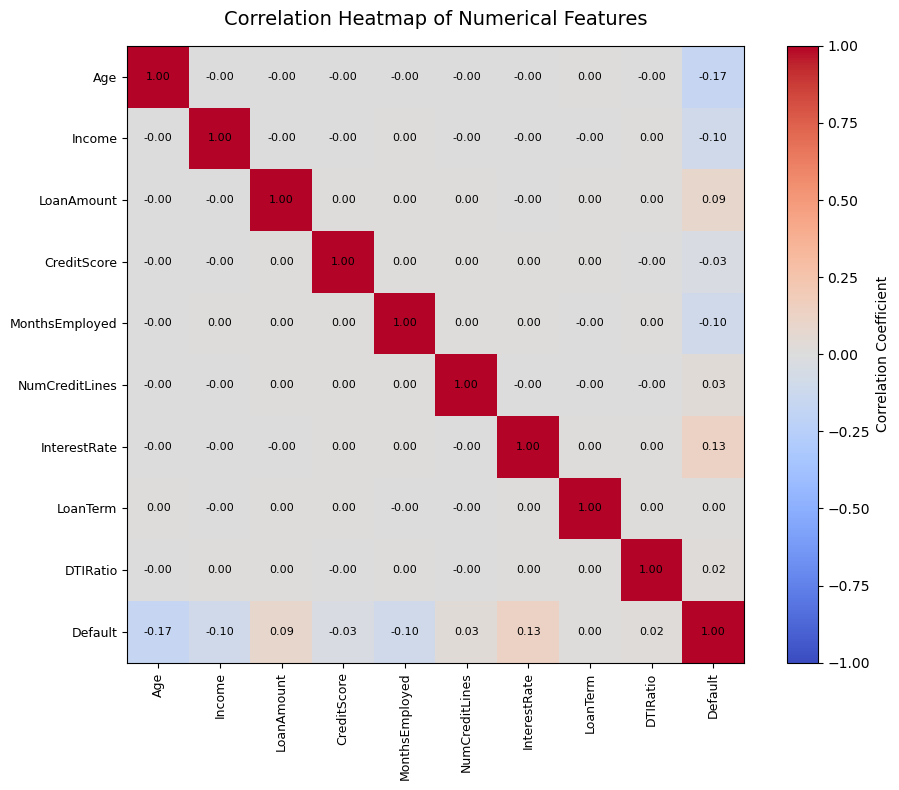

In [23]:
# Figure 3.7 - Correlation Heatmap of Numerical Features

import matplotlib.pyplot as plt
import numpy as np

# Select numerical columns
numeric_df = df.select_dtypes(include=['number'])

# Calculate correlation matrix
corr = numeric_df.corr()

# Create figure
plt.figure(figsize=(10, 8))

# Plot heatmap
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)

# Add color bar
plt.colorbar(label='Correlation Coefficient')

# Axis labels
plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=90,
    fontsize=9
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns,
    fontsize=9
)

# Display correlation values inside each cell
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(
            j,
            i,
            f"{corr.iloc[i, j]:.2f}",
            ha='center',
            va='center',
            fontsize=8,
            color='black'
        )

# Title
plt.title(
    "Correlation Heatmap of Numerical Features",
    fontsize=14,
    pad=15
)

plt.tight_layout()

# Save figure
plt.savefig(
    "Figure_3_7_Correlation_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report
)

In [25]:
df = df.copy()

encoder = LabelEncoder()

for col in df.select_dtypes(include='object').columns:
    df[col] = encoder.fit_transform(df[col])

df.head()

<ipython-input-25-1418fb0e2d62>:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,128027,56,85994,50587,520,80,4,15.23,36,0.44,0,0,0,1,1,4,1,0
1,125442,69,50432,124440,458,15,1,4.81,60,0.68,2,0,1,0,0,4,1,0
2,85333,46,84208,129188,451,26,3,21.17,24,0.31,2,3,0,1,1,0,0,1
3,220129,32,31713,44799,743,0,3,7.07,24,0.23,1,0,1,0,0,1,0,0
4,105746,60,20437,9139,633,8,4,6.51,48,0.73,0,3,0,0,1,0,0,0


In [30]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop("Default", axis=1)
y = df["Default"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Scale the features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(X_train.shape)
print(X_test.shape)

(204277, 17)
(51070, 17)


In [31]:
lr = LogisticRegression(
    max_iter=2000,
    random_state=42
)

lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)
lr_prob = lr.predict_proba(X_test)[:, 1]

print("Logistic Regression Completed")

Logistic Regression Completed


In [32]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train,y_train)

rf_pred = rf.predict(X_test)

rf_prob = rf.predict_proba(X_test)[:,1]

print("Random Forest Completed")

Random Forest Completed


In [33]:
gb = GradientBoostingClassifier(
    random_state=42
)

gb.fit(X_train,y_train)

gb_pred = gb.predict(X_test)

gb_prob = gb.predict_proba(X_test)[:,1]

print("Gradient Boosting Completed")

Gradient Boosting Completed


In [34]:
results = pd.DataFrame({

'Model':[
    'Logistic Regression',
    'Random Forest',
    'Gradient Boosting'
],

'Accuracy':[

accuracy_score(y_test,lr_pred),

accuracy_score(y_test,rf_pred),

accuracy_score(y_test,gb_pred)

],

'Precision':[

precision_score(y_test,lr_pred),

precision_score(y_test,rf_pred),

precision_score(y_test,gb_pred)

],

'Recall':[

recall_score(y_test,lr_pred),

recall_score(y_test,rf_pred),

recall_score(y_test,gb_pred)

],

'F1 Score':[

f1_score(y_test,lr_pred),

f1_score(y_test,rf_pred),

f1_score(y_test,gb_pred)

],

'ROC AUC':[

roc_auc_score(y_test,lr_prob),

roc_auc_score(y_test,rf_prob),

roc_auc_score(y_test,gb_prob)

]

})

print(results)

                 Model  Accuracy  Precision    Recall  F1 Score   ROC AUC
0  Logistic Regression  0.885902   0.623729  0.031186  0.059403  0.749786
1        Random Forest  0.886920   0.659033  0.043898  0.082314  0.733753
2    Gradient Boosting  0.887351   0.654088  0.052881  0.097852  0.756605


In [35]:
print("LOGISTIC REGRESSION")
print(classification_report(y_test,lr_pred))

print("-------------------------")

print("RANDOM FOREST")
print(classification_report(y_test,rf_pred))

print("-------------------------")

print("GRADIENT BOOSTING")
print(classification_report(y_test,gb_pred))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     45170
           1       0.62      0.03      0.06      5900

    accuracy                           0.89     51070
   macro avg       0.76      0.51      0.50     51070
weighted avg       0.86      0.89      0.84     51070

-------------------------
RANDOM FOREST
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     45170
           1       0.66      0.04      0.08      5900

    accuracy                           0.89     51070
   macro avg       0.77      0.52      0.51     51070
weighted avg       0.86      0.89      0.84     51070

-------------------------
GRADIENT BOOSTING
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     45170
           1       0.65      0.05      0.10      5900

    accuracy                           0.89     51070
   macro avg       0.77 

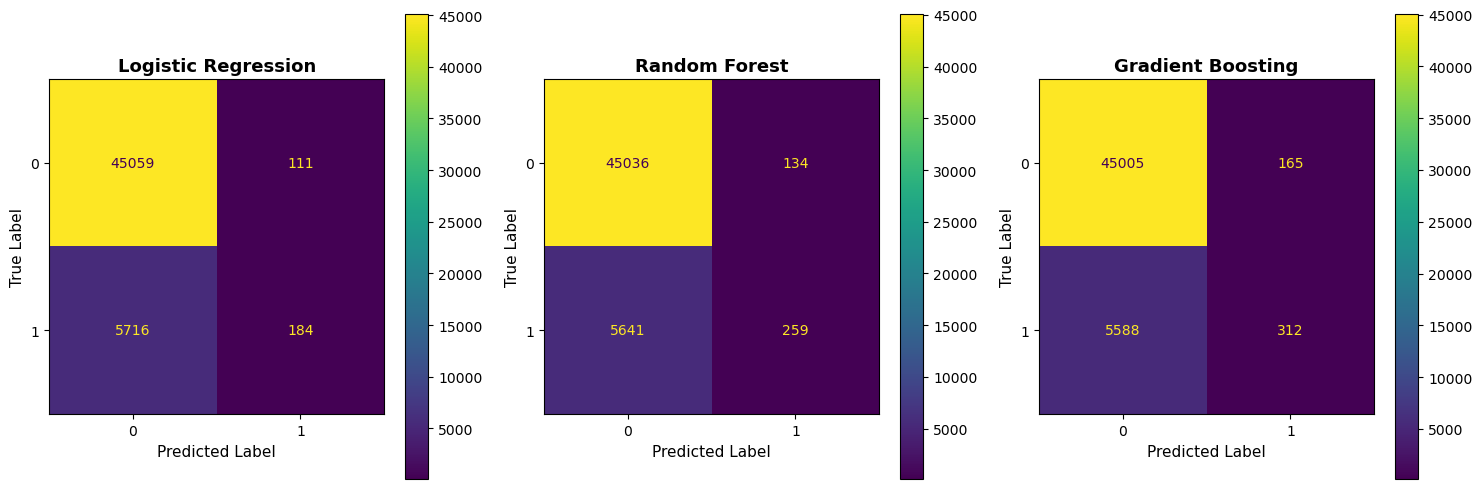

In [42]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Models and titles
models = [lr, rf, gb]
titles = ["Logistic Regression", "Random Forest", "Gradient Boosting"]

# Create figure
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, model, title in zip(axes, models, titles):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        cmap="viridis",
        colorbar=True,
        ax=ax
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Predicted Label", fontsize=11)
    ax.set_ylabel("True Label", fontsize=11)
    ax.tick_params(axis='both', labelsize=10)

plt.tight_layout()

# Save the figure
plt.savefig("Figure_4_2_Confusion_Matrices.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

<Figure size 800x600 with 0 Axes>

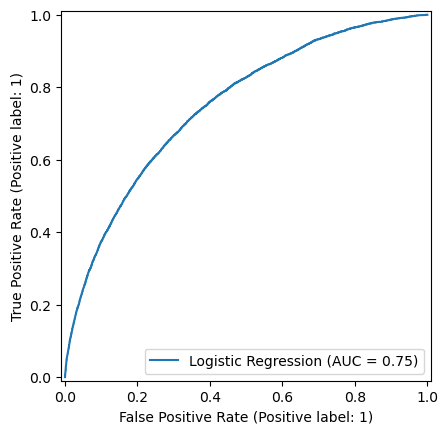

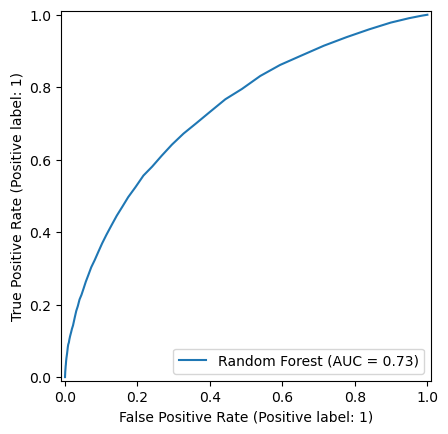

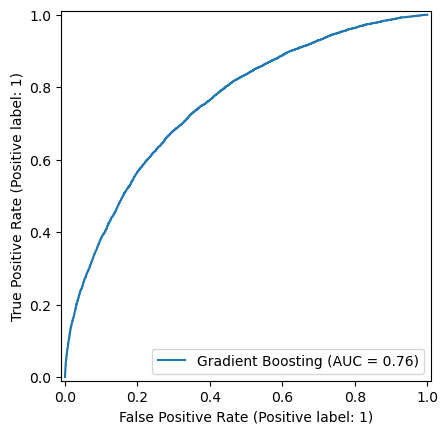

In [37]:
plt.figure(figsize=(8,6))

RocCurveDisplay.from_predictions(y_test,lr_prob,name="Logistic Regression")

RocCurveDisplay.from_predictions(y_test,rf_prob,name="Random Forest")

RocCurveDisplay.from_predictions(y_test,gb_prob,name="Gradient Boosting")

plt.savefig("ROC_Curve.png",dpi=300)

plt.show()

In [38]:
importance = pd.DataFrame({

'Feature':X.columns,

'Importance':rf.feature_importances_

})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

           Feature  Importance
2           Income    0.120599
7     InterestRate    0.114487
3       LoanAmount    0.109021
0           LoanID    0.094169
4      CreditScore    0.092954
1              Age    0.092074
5   MonthsEmployed    0.088708
9         DTIRatio    0.080279
8         LoanTerm    0.034778
15     LoanPurpose    0.034240
10       Education    0.028240
6   NumCreditLines    0.027822
11  EmploymentType    0.026082
12   MaritalStatus    0.022608
13     HasMortgage    0.013323
14   HasDependents    0.011167
16     HasCoSigner    0.009450


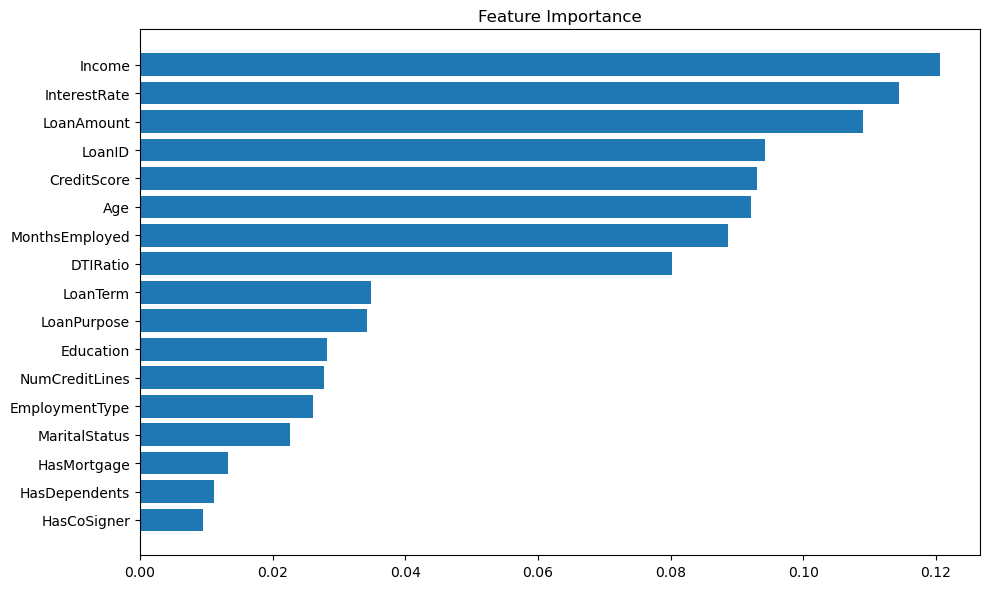

In [39]:
plt.figure(figsize=(10,6))

plt.barh(
    importance['Feature'],
    importance['Importance']
)

plt.gca().invert_yaxis()

plt.title("Feature Importance")

plt.tight_layout()

plt.savefig("Feature_Importance.png",dpi=300)

plt.show()

In [41]:
dir()

['ConfusionMatrixDisplay',
 'GradientBoostingClassifier',
 'In',
 'LabelEncoder',
 'LogisticRegression',
 'Out',
 'RandomForestClassifier',
 'RocCurveDisplay',
 'StandardScaler',
 'X',
 'X_test',
 'X_train',
 '_',
 '_12',
 '_13',
 '_25',
 '_9',
 '__',
 '___',
 '__builtin__',
 '__builtins__',
 '__name__',
 '_dh',
 '_i',
 '_i1',
 '_i10',
 '_i11',
 '_i12',
 '_i13',
 '_i14',
 '_i15',
 '_i16',
 '_i17',
 '_i18',
 '_i19',
 '_i2',
 '_i20',
 '_i21',
 '_i22',
 '_i23',
 '_i24',
 '_i25',
 '_i26',
 '_i27',
 '_i28',
 '_i29',
 '_i3',
 '_i30',
 '_i31',
 '_i32',
 '_i33',
 '_i34',
 '_i35',
 '_i36',
 '_i37',
 '_i38',
 '_i39',
 '_i4',
 '_i40',
 '_i41',
 '_i5',
 '_i6',
 '_i7',
 '_i8',
 '_i9',
 '_ih',
 '_ii',
 '_iii',
 '_oh',
 'accuracy_score',
 'axes',
 'bar',
 'bars',
 'classification_report',
 'col',
 'confusion_matrix',
 'corr',
 'counts',
 'df',
 'encoder',
 'exit',
 'f1_score',
 'fig',
 'gb',
 'gb_pred',
 'gb_prob',
 'get_ipython',
 'height',
 'i',
 'importance',
 'j',
 'lr',
 'lr_pred',
 'lr_prob',
 

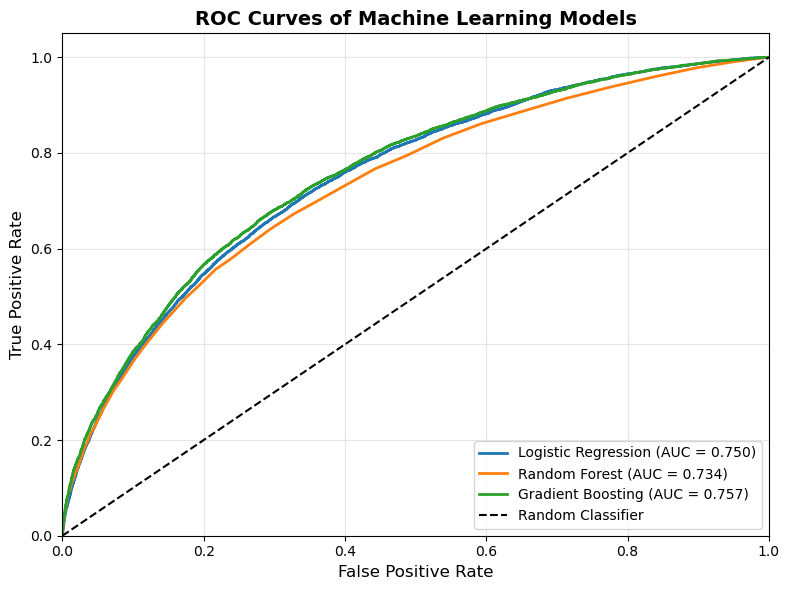

In [43]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Compute ROC curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_prob)
roc_auc_lr = auc(fpr_lr, tpr_lr)

fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)
roc_auc_rf = auc(fpr_rf, tpr_rf)

fpr_gb, tpr_gb, _ = roc_curve(y_test, gb_prob)
roc_auc_gb = auc(fpr_gb, tpr_gb)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(fpr_lr, tpr_lr,
         linewidth=2,
         label=f'Logistic Regression (AUC = {roc_auc_lr:.3f})')

plt.plot(fpr_rf, tpr_rf,
         linewidth=2,
         label=f'Random Forest (AUC = {roc_auc_rf:.3f})')

plt.plot(fpr_gb, tpr_gb,
         linewidth=2,
         label=f'Gradient Boosting (AUC = {roc_auc_gb:.3f})')

# Random classifier line
plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Classifier')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curves of Machine Learning Models', fontsize=14, fontweight='bold')

plt.legend(loc='lower right', fontsize=10)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("Figure_4_3_ROC_Curves.png", dpi=300, bbox_inches="tight")
plt.show()

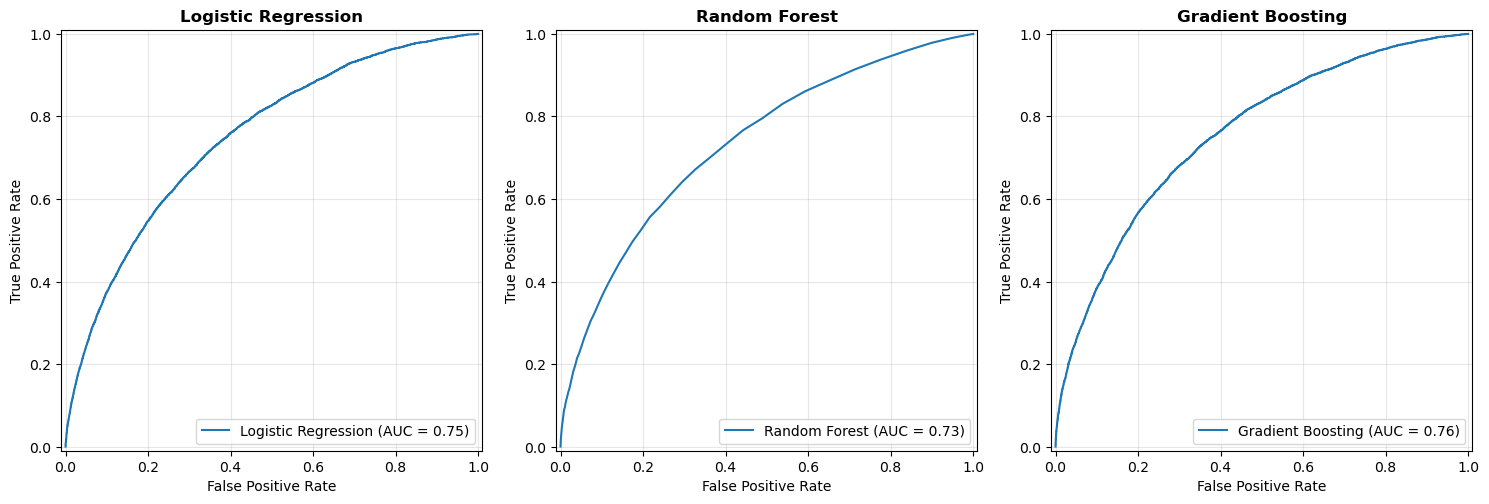

In [44]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# Create three subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Logistic Regression
RocCurveDisplay.from_estimator(
    lr,
    X_test,
    y_test,
    ax=axes[0],
    name="Logistic Regression"
)
axes[0].set_title("Logistic Regression", fontsize=12, fontweight="bold")

# Random Forest
RocCurveDisplay.from_estimator(
    rf,
    X_test,
    y_test,
    ax=axes[1],
    name="Random Forest"
)
axes[1].set_title("Random Forest", fontsize=12, fontweight="bold")

# Gradient Boosting
RocCurveDisplay.from_estimator(
    gb,
    X_test,
    y_test,
    ax=axes[2],
    name="Gradient Boosting"
)
axes[2].set_title("Gradient Boosting", fontsize=12, fontweight="bold")

# Improve appearance
for ax in axes:
    ax.grid(alpha=0.3)
    ax.set_xlabel("False Positive Rate", fontsize=10)
    ax.set_ylabel("True Positive Rate", fontsize=10)

plt.tight_layout()

# Save high-quality image
plt.savefig("Figure_4_3_ROC_Curves.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

## Key Findings

- Gradient Boosting achieved the strongest overall performance among the three tested models based on ROC-AUC, Recall, and F1-score.
- Gradient Boosting achieved **88.74% accuracy** and **75.66% ROC-AUC** on the test set.
- Random Forest feature importance ranked **Income (0.1206)**, **Interest Rate (0.1145)**, and **Loan Amount (0.1090)** among the strongest variables.
- The relatively low Recall and F1-score indicate the effect of class imbalance, so accuracy should not be considered the only performance measure.

## Conclusion

The analysis demonstrates an end-to-end workflow for financial risk assessment, from exploratory analysis and preprocessing to model comparison and feature-importance analysis.
